In [1]:
import pandas as pd  # library untuk membaca dan mengolah tabel

# Baca file anotasi manual (path relatif dari folder notebooks)
df = pd.read_csv("../data/raw/EmoTweetID-Human.csv")

print("Bentuk tabel (baris, kolom):", df.shape)
print("Nama kolom:", df.columns.tolist())
df.head(10)  # tampilkan 10 baris pertama

Bentuk tabel (baris, kolom): (2243, 3)
Nama kolom: ['Unnamed: 0', 'tweet', 'label']


,Unnamed: 0,tweet,label
0,0,wah belom liat muka gue lagi murka hahahaha,joy
1,1,Mungkin kurang piknik adrenalin. Mereka yg ske...,anger
2,2,"maaf kalo tersinggung ""orang kurus cepet mati""...",anger
3,3,berserah pada maha esa paling tabah dan sabar ...,joy
4,4,Ehekk malu la hahahahahahaha,sadness
5,5,WKWKWKWK KESAL AKU BACANYA TAPI KOK SENYUM2,anger
6,6,Yg membuat lidahku. Gugup tak bergerak,fear
7,7,Lho kok buru-buru mengatakan orang marah? Kekn...,disgust
8,8,Gila sih itu ngeri bgt galiannya,fear
9,9,"Kesal masih belom, ngantuk iya",anger


In [2]:
# 1) Label apa saja yang ada, dan berapa jumlah tiap label
print("Jumlah tiap label:")
print(df["label"].value_counts())

# 2) Proporsi tiap label dalam persen
print("\nProporsi (%):")
print((df["label"].value_counts(normalize=True) * 100).round(1))

# 3) Apakah ada data kosong di tiap kolom
print("\nData kosong per kolom:")
print(df.isna().sum())

# 4) Berapa tweet yang persis sama (duplikat)
print("\nJumlah tweet duplikat:", df["tweet"].duplicated().sum())

Jumlah tiap label:
label
anger       475
joy         429
fear        395
disgust     355
sadness     303
surprise    286
Name: count, dtype: int64

Proporsi (%):
label
anger       21.2
joy         19.1
fear        17.6
disgust     15.8
sadness     13.5
surprise    12.8
Name: proportion, dtype: float64

Data kosong per kolom:
Unnamed: 0    0
tweet         0
label         0
dtype: int64

Jumlah tweet duplikat: 29


In [3]:
# Agar teks tweet tidak terpotong saat ditampilkan
pd.set_option("display.max_colwidth", 100)

# Ambil semua baris yang teksnya muncul lebih dari sekali
dup = df[df["tweet"].duplicated(keep=False)].sort_values("tweet")
print("Jumlah baris yang terlibat duplikat:", len(dup))

# Untuk tiap teks duplikat, cek apakah labelnya sama atau berbeda
jumlah_label = dup.groupby("tweet")["label"].nunique()
print("Jumlah teks unik yang duplikat:", len(jumlah_label))
print("Dari itu, yang labelnya BERBEDA:", (jumlah_label > 1).sum())

# Tampilkan 20 baris pertama sebagai contoh
dup[["tweet", "label"]].head(20)

Jumlah baris yang terlibat duplikat: 54
Jumlah teks unik yang duplikat: 25
Dari itu, yang labelnya BERBEDA: 14


,tweet,label
589,AKU NIH PENAKUT N BATUK DAH AH PENAT AH KLU NK MATI MATI CPT NNT KENA HADAP BENDA SMUA KENA BELA...,anger
778,AKU NIH PENAKUT N BATUK DAH AH PENAT AH KLU NK MATI MATI CPT NNT KENA HADAP BENDA SMUA KENA BELA...,fear
931,Aku masih sedih. Aku masih marah. Aku masih kecewa. Aku masih ingin berteriak. Tapi aku tak dend...,anger
595,Aku masih sedih. Aku masih marah. Aku masih kecewa. Aku masih ingin berteriak. Tapi aku tak dend...,anger
1675,"Aku nih udah cemas, takut skripsi banyak revisian",fear
939,"Aku nih udah cemas, takut skripsi banyak revisian",fear
498,Bangga bgt,joy
1757,Bangga bgt,joy
1468,Bikin Senang.,joy
1541,Bikin Senang.,joy


In [4]:
n_awal = len(df)

# Hitung berapa label berbeda untuk tiap teks
jumlah_label = df.groupby("tweet")["label"].transform("nunique")

# 1) Buang semua salinan teks yang labelnya bertentangan
tanpa_konflik = df[jumlah_label == 1]
n_konflik = n_awal - len(tanpa_konflik)

# 2) Untuk teks duplikat berlabel sama, simpan satu salinan saja
bersih = tanpa_konflik.drop_duplicates(subset="tweet", keep="first")
n_duplikat_sama = len(tanpa_konflik) - len(bersih)

# 3) Ambil hanya kolom yang dipakai, lalu rapikan nomor baris
bersih = bersih[["tweet", "label"]].reset_index(drop=True)

print("Jumlah awal           :", n_awal)
print("Dibuang (label konflik):", n_konflik)
print("Dibuang (duplikat sama):", n_duplikat_sama)
print("Jumlah akhir          :", len(bersih))
print()
print(bersih["label"].value_counts())

# Simpan ke data/processed (folder ini diabaikan Git)
bersih.to_csv("../data/processed/emotweetid_clean.csv", index=False)

Jumlah awal           : 2243
Dibuang (label konflik): 29
Dibuang (duplikat sama): 14
Jumlah akhir          : 2200

label
anger       465
joy         418
fear        387
disgust     350
sadness     298
surprise    282
Name: count, dtype: int64


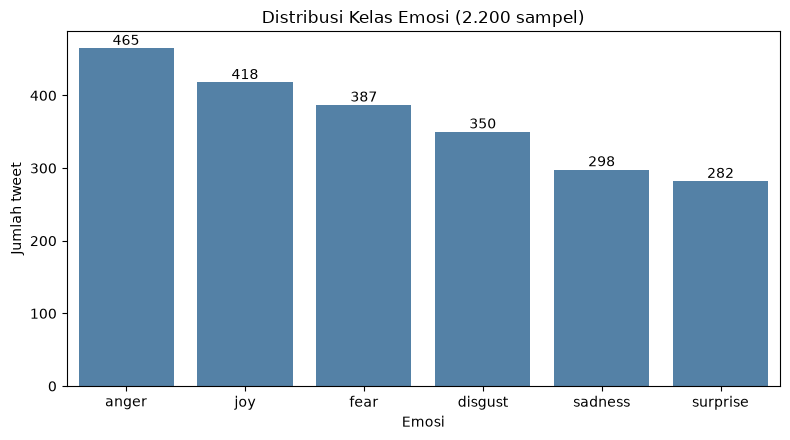

In [2]:
import os
import pandas as pd              # library untuk membaca dan mengolah tabel
import matplotlib.pyplot as plt  # library untuk membuat grafik
import seaborn as sns            # pelengkap matplotlib agar grafik lebih rapi

# Baca data versi bersih (2.200 sampel)
bersih = pd.read_csv("../data/processed/emotweetid_clean.csv")

# Siapkan folder penyimpanan grafik (dibuat jika belum ada)
os.makedirs("../reports/figures", exist_ok=True)

# Urutkan emosi dari yang paling banyak ke paling sedikit
urutan = bersih["label"].value_counts().index

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=bersih, x="label", order=urutan, color="steelblue")

# Tulis angka jumlah di atas tiap batang
for wadah in ax.containers:
    ax.bar_label(wadah)

plt.title("Distribusi Kelas Emosi (2.200 sampel)")
plt.xlabel("Emosi")
plt.ylabel("Jumlah tweet")
plt.tight_layout()

# Simpan sebagai gambar untuk laporan, lalu tampilkan
plt.savefig("../reports/figures/distribusi_kelas.png", dpi=150)
plt.show()

       jumlah_kata  jumlah_karakter
count       2200.0           2200.0
mean          17.1            102.7
std           12.8             77.5
min            1.0              5.0
25%            7.0             40.0
50%           13.0             78.0
75%           25.0            147.0
max           66.0            284.0


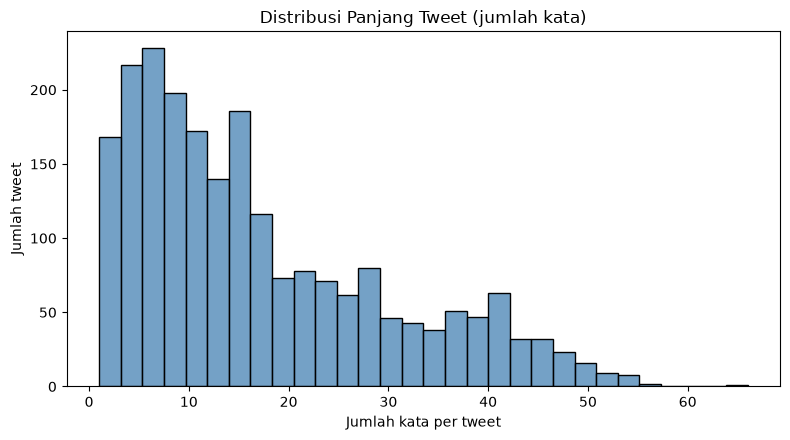

In [3]:
# Hitung jumlah kata dan jumlah karakter tiap tweet
bersih["jumlah_kata"] = bersih["tweet"].str.split().str.len()
bersih["jumlah_karakter"] = bersih["tweet"].str.len()

# Ringkasan angka: rata-rata, terkecil, terbesar, dan lainnya
print(bersih[["jumlah_kata", "jumlah_karakter"]].describe().round(1))

# Histogram: berapa banyak tweet untuk tiap rentang panjang kata
plt.figure(figsize=(8, 4.5))
sns.histplot(data=bersih, x="jumlah_kata", bins=30, color="steelblue")
plt.title("Distribusi Panjang Tweet (jumlah kata)")
plt.xlabel("Jumlah kata per tweet")
plt.ylabel("Jumlah tweet")
plt.tight_layout()
plt.savefig("../reports/figures/panjang_teks.png", dpi=150)
plt.show()

In [5]:
# Tampilkan teks tweet secara penuh (tidak terpotong)
pd.set_option("display.max_colwidth", None)

# Untuk tiap emosi, ambil 3 tweet acak (random_state agar hasilnya selalu sama)
for emosi in sorted(bersih["label"].unique()):
    print("=====", emosi.upper(), "=====")
    contoh = bersih[bersih["label"] == emosi].sample(3, random_state=42)
    for teks in contoh["tweet"]:
        print("-", teks)
    print()

===== ANGER =====
- Kesal w njir
- Kok urang tersinggung yah
- Saya murka

===== DISGUST =====
- Eh sumpah ya min muak juga lama2 sama yg jualan di repan yaampun mmf ya tapi mengganggu bgt huhu, blok tuh bole
- Bukan rekat atau retak, lebih ke jijik karena keliatan banget isinya tak lebih dari sekedar kumpulan orang2 munafik yg slalu ngomongin agama tapi praktek di kehidupan nyata NOL besar, jauh dari yg diomongin di WAG
- aku punya temen yg mukanya berminyak parah tp ga pernah mau di lap in pdhl waktu itu aku udh nyoba nawarin oil control punyaku but she said no. aku ga ngerti tp dia merasa mukanya glowing with that looks, is it just me or emg it looks weird? krn aku kaya risih aja dk why(?)

===== FEAR =====
- Ga kebayang kalo injun murka
- Mo ngakak, takut dosa
- Min, boleh bawa gitar yg ada softcase nya gak kedalam pesawat? Soalnya takut dibanting kalau masuk bagasi. Tks

===== JOY =====
- Alhamdulillah Mbak Syantik..... W0ng Nd3So ma emang MissQueen Tapi tak membuat MissQuenn Pema